# CPNO UNISIM-I-D - V1a (Chebyshev Polynomial Neural Operator) - Colab

**Technique:** mesh-free CPNO, purely data-driven, faithful to Algorithm 1 of the paper (no UNISIM-specific adaptations). **Version:** V1a. **Date:** 10/05/2026.

Learns the operator `(x, y, t, RATE_INJ1, LRAT_NA2) -> (Sw, P)` with the same 50-scenario dataset used by DeepONet. It contains no PDE residual and generates no new OPM simulations. `K` (permeability) does NOT enter as a feature: it is fixed across the 50 scenarios and Algorithm 1 has no mechanism for spatially varying fields other than `theta` -- any effect of `K`, if present, must be learned implicitly from `(x,y)` on this single fixed geology.

**Closed design (pure V1a):**
- `h^(0) = Phi(x,y,t)` -- Chebyshev `T_0..T_P` encoding, WITHOUT appended UNISIM features (eq.3, Algorithm 1 line 3, p.6);
- fixed hidden width `d_h=64`, independent of `P`, matching the paper's own experimental setup (p.10 Sec.3: "4 hidden layers and width 64", confirmed fixed across the `P` and `q` ablations, Sec.3.5.1-3.5.2); `A_0` (linear, no activation) embeds `Phi` into `d_h` to reconcile that fixed width with `h^(0)=Phi`;
- well rates via FiLM modulation across `q` polynomial layers (eq.12-13, Algorithm 1) -- the ONLY place where `theta=(RATE_INJ1,LRAT_NA2)` enters;
- final linear projection, WITHOUT sigmoid or any other output constraint (eq.4 / Algorithm 1 line 10) -- `Sw` can fall outside `[0,1]`, measured as a diagnostic (Section 8);
- pressure standardized per fold; `Sw` left unnormalized;
- 5x k-fold validation (40 train / 10 val) and ablation of `P` and `q` (same protocol as the paper's Sec.3.5: `d_h` fixed, one factor swept at a time);
- online point sampling over active cells: it never materializes the ~7-million-point table;
- Section 10: ablation plots, k-fold, field maps (interactive) and parity plot -- same criterion as Section 8 of the DeepONet notebook.

**Deferred to V1b (future, out of scope for V1a):** reintroduce `logK` and distances to wells as static features, and `sigmoid` on `Sw` -- the UNISIM adaptations that the first implementation of this notebook mistakenly included inside "V1a". They are measured separately so that any improvement can be attributed specifically to those adaptations (same *ceteris paribus* criterion used for the data-driven-vs-physics-informed decision, artifact Sec.3.3).

Reference: Chen et al. (2026), *Physics-Informed Chebyshev Polynomial Neural Operator for Parametric PDEs*, arXiv:2602.01737. Tech-plan: Traycer artifact `chebyshev-unisim1-arquitectura`.

| Version | Date | Change |
|---|---|---|
| V1a | 10/05/2026 | Initial data-driven implementation, k-fold, `P/q` ablation, final model and checkpoint |
| V1a | 10/05/2026 | Correction: removed `logK`, distances to wells and `sigmoid` -- they were not in Algorithm 1; V1a stays pure, those adaptations were deferred to V1b |
| V1a | 10/05/2026 | Added Section 10 (plots): `P`/`q` ablation, k-fold per fold, interactive field maps and parity plot -- the notebook previously had no plots at all |

In [1]:
# -- CELL 1 - Imports, seed and device --
import copy
import datetime
import json
import random
import time
import warnings
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import ipywidgets as widgets
from ipywidgets import interact

warnings.filterwarnings("ignore")

VERSION_ID = "V1a"
TECNICA_ID = "CPNO"
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"{TECNICA_ID} {VERSION_ID} - device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

CPNO V1a - device: cuda
GPU: Tesla T4


## 1. Shared dataset

On Colab the existing `.h5` on Drive is used. Locally an explicit fallback is used. The file is loaded once into RAM; inactive cells are never sampled.

In [2]:
# -- CELL 2 - Dataset loading --
IN_COLAB = Path("/content").exists()

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL")
    DATASET_PATH = BASE_DIR / "datasets" / "unisim1_deeponet_dataset.h5"
    OUTPUT_DIR = BASE_DIR / "Chebyshev" / "models"
else:
    DATASET_PATH = Path(
        r"C:\Users\guita\Desktop\PhD-ScimL-New\Analisis de PINNS\Claude\OPM"
        r"\OPERADOR NEURAL\unisim1_deeponet_dataset.h5"
    )
    OUTPUT_DIR = DATASET_PATH.parent / "models" / "cpno"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
if not DATASET_PATH.exists():
    extra = (
        "\nYou are on Colab: place unisim1_deeponet_dataset.h5 in "
        "'MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL/datasets/'." if IN_COLAB else
        "\nAdjust DATASET_PATH if the file is in another local location."
    )
    raise FileNotFoundError(f"Could not find the dataset: {DATASET_PATH}." + extra)

with h5py.File(DATASET_PATH, "r") as f:
    actnum = f["static/actnum"][:].astype(bool)
    params = f["scenarios/params"][:].astype(np.float32)
    time_days = f["scenarios/time_days"][:].astype(np.float32)
    swat = f["scenarios/swat"][:].astype(np.float32)
    pressure = f["scenarios/pressure"][:].astype(np.float32)

N_ESCENARIOS, N_T, NX, NY = swat.shape
active_ij = np.argwhere(actnum).astype(np.int64)
N_ACTIVE = len(active_ij)

assert pressure.shape == swat.shape == (50, 61, 81, 58)
assert params.shape == (50, 2)
assert np.isfinite(swat[:, :, actnum]).all()
assert np.isfinite(pressure[:, :, actnum]).all()

print(f"Environment: {'Colab' if IN_COLAB else 'local'}")
print(f"Dataset: {DATASET_PATH}")
print(f"Grid: {NX}x{NY} | active: {N_ACTIVE} ({100 * actnum.mean():.1f}%)")
print(f"Scenarios: {N_ESCENARIOS} | time steps: {N_T} | total points: {N_ESCENARIOS*N_T*N_ACTIVE:,}")
print("Pure V1a: K (permx/permy) is not loaded -- it is not a model feature (see header).")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment: Colab
Dataset: /content/drive/MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL/datasets/unisim1_deeponet_dataset.h5
Grid: 81x58 | active: 2296 (48.9%)
Scenarios: 50 | time steps: 61 | total points: 7,002,800
Pure V1a: K (permx/permy) is not loaded -- it is not a model feature (see header).


## 2. Pointwise features and normalization

Active coordinates and time are mapped to [-1,1] (eq.9). Rates use the physical LHS ranges for the FiLM modulation -- the only `theta` input. Pressure is normalized afterwards, exclusively with each fold's training scenarios; `Sw` is left unnormalized and unbounded (see Sections 3 and 8).

In [3]:
# -- CELL 3 - Active coordinates and targets (no UNISIM features, see header) --
RATE_INJ1_RANGE = (2000.0, 6000.0)
LRAT_NA2_RANGE = (1500.0, 4500.0)

active_i = active_ij[:, 0]
active_j = active_ij[:, 1]

def affine_to_minus1_plus1(values, vmin, vmax):
    return (2.0 * (values - vmin) / (vmax - vmin) - 1.0).astype(np.float32)

x_active = affine_to_minus1_plus1(active_i, active_i.min(), active_i.max())
y_active = affine_to_minus1_plus1(active_j, active_j.min(), active_j.max())
t_norm = affine_to_minus1_plus1(time_days, time_days.min(), time_days.max())

theta_norm = np.empty_like(params, dtype=np.float32)
theta_norm[:, 0] = affine_to_minus1_plus1(params[:, 0], *RATE_INJ1_RANGE)
theta_norm[:, 1] = affine_to_minus1_plus1(params[:, 1], *LRAT_NA2_RANGE)

# Active cells only: (scenario, time, active_cell).
sw_active = swat[:, :, actnum]
p_active = pressure[:, :, actnum]

assert sw_active.shape == p_active.shape == (N_ESCENARIOS, N_T, N_ACTIVE)
print(f"active coords: {x_active.shape} | theta: {theta_norm.shape}")
print(f"active Sw: [{sw_active.min():.4f}, {sw_active.max():.4f}]")
print(f"active P:  [{p_active.min():.2f}, {p_active.max():.2f}]")

active coords: (2296,) | theta: (50, 2)
active Sw: [0.1656, 1.0000]
active P:  [264.69, 483.97]


## 3. CPNO architecture

`chebyshev_features` uses the stable three-term recurrence. `h^(0)` is a linear projection of `Phi` (no UNISIM features appended, see header). Each layer multiplies a learned projection of `Phi` by the hidden state and applies FiLM modulation generated from the two rates. There is no branch/trunk: the internal Hadamard product raises the polynomial capacity (eq.12).

In [4]:
# -- CELL 4 - Chebyshev encoding and CPNO model --
def chebyshev_1d(z, order):
    # T_0..T_order for z of shape (..., 1), output (..., order+1).
    terms = [torch.ones_like(z)]
    if order >= 1:
        terms.append(z)
    for _ in range(2, order + 1):
        terms.append(2.0 * z * terms[-1] - terms[-2])
    return torch.cat(terms, dim=-1)


def chebyshev_features(coords, order):
    return torch.cat([chebyshev_1d(coords[:, d:d+1], order) for d in range(3)], dim=-1)


class ModulatedPolynomialLayer(nn.Module):
    def __init__(self, phi_dim, hidden_dim, modulation_dim=32):
        super().__init__()
        self.poly = nn.Linear(phi_dim, hidden_dim)
        self.modulation = nn.Sequential(
            nn.Linear(2, modulation_dim),
            nn.GELU(),
            nn.Linear(modulation_dim, 2 * hidden_dim),
        )
        # Start close to identity modulation: omega=1, bias=0.
        nn.init.zeros_(self.modulation[-1].weight)
        nn.init.zeros_(self.modulation[-1].bias)

    def forward(self, phi, theta, hidden):
        omega_raw, bias = self.modulation(theta).chunk(2, dim=-1)
        omega = 1.0 + omega_raw
        return torch.nn.functional.gelu(omega * (self.poly(phi) * hidden) + bias)


class CPNOUNISIM(nn.Module):
    def __init__(self, order=6, depth=6, hidden_dim=64, modulation_dim=32):
        super().__init__()
        self.order = order
        self.depth = depth
        self.hidden_dim = hidden_dim
        self.phi_dim = 3 * (order + 1)
        # A_0: embeds Phi(x,y,t) into the paper's working width d_h=64 (p.10 Sec.3,
        # "4 hidden layers and width 64"), reconciling that fixed width with h^(0)=Phi(x,t)
        # from eq.3 / Algorithm 1 line 3 (dim(Phi) varies with P, d_h does not). Linear, no
        # activation and no UNISIM features -- same nature as the rest of A_j (eq.12).
        self.entry = nn.Linear(self.phi_dim, hidden_dim)
        self.layers = nn.ModuleList([
            ModulatedPolynomialLayer(self.phi_dim, hidden_dim, modulation_dim)
            for _ in range(depth)
        ])
        self.projection = nn.Linear(hidden_dim, 2)

    def forward(self, coords, theta):
        phi = chebyshev_features(coords, self.order)
        hidden = self.entry(phi)
        for layer in self.layers:
            hidden = layer(phi, theta, hidden)
        return self.projection(hidden)  # (raw_Sw, raw_P) -- eq.4/Algorithm 1 line 10, no activation


model_test = CPNOUNISIM(order=6, depth=6).to(device)
n_params_test = sum(p.numel() for p in model_test.parameters() if p.requires_grad)
with torch.no_grad():
    y_test = model_test(
        torch.zeros(8, 3, device=device),
        torch.zeros(8, 2, device=device),
    )
assert y_test.shape == (8, 2) and torch.isfinite(y_test).all()
print(f"CPNO baseline P=6, q=6: {n_params_test:,} parameters")

CPNO baseline P=6, q=6: 35,906 parameters


## 4. Sampling, training and evaluation

Each step uniformly picks a training scenario, snapshot and active cell. Evaluation exhaustively sweeps every point of the validation scenarios in chunks and accumulates `rel_l2` without storing giant prediction arrays.

In [5]:
# -- CELL 5 - Sampling and metric utilities --
def pressure_stats(train_idx):
    values = p_active[np.asarray(train_idx)]
    return float(values.mean()), float(values.std())


def make_batch(scenario_pool, batch_size, p_mu, p_sigma, rng):
    e = rng.choice(scenario_pool, size=batch_size)
    ti = rng.integers(0, N_T, size=batch_size)
    ci = rng.integers(0, N_ACTIVE, size=batch_size)

    coords = np.stack([x_active[ci], y_active[ci], t_norm[ti]], axis=1)
    targets = np.stack([sw_active[e, ti, ci], (p_active[e, ti, ci] - p_mu) / p_sigma], axis=1)
    return (
        torch.from_numpy(coords).to(device),
        torch.from_numpy(theta_norm[e]).to(device),
        torch.from_numpy(targets.astype(np.float32)).to(device),
    )


@torch.inference_mode()
def evaluate_model(model, scenario_idx, p_mu, p_sigma, chunk_size=65536):
    model.eval()
    numerators = np.zeros(2, dtype=np.float64)
    denominators = np.zeros(2, dtype=np.float64)

    cell_chunks = max(1, chunk_size // N_T)
    for e in np.asarray(scenario_idx):
        for start in range(0, N_ACTIVE, cell_chunks):
            stop = min(start + cell_chunks, N_ACTIVE)
            cells = np.arange(start, stop)
            ti = np.tile(np.arange(N_T), len(cells))
            ci = np.repeat(cells, N_T)
            n = len(ci)

            coords_np = np.stack([x_active[ci], y_active[ci], t_norm[ti]], axis=1)
            pred = model(
                torch.from_numpy(coords_np).to(device),
                torch.from_numpy(np.repeat(theta_norm[e:e+1], n, axis=0)).to(device),
            ).cpu().numpy()
            pred[:, 1] = pred[:, 1] * p_sigma + p_mu
            truth = np.stack([sw_active[e, ti, ci], p_active[e, ti, ci]], axis=1)
            numerators += ((pred - truth) ** 2).sum(axis=0, dtype=np.float64)
            denominators += (truth ** 2).sum(axis=0, dtype=np.float64)

    return np.sqrt(numerators / denominators)


def train_model(train_idx, order, depth, n_steps, batch_size, lr, seed, verbose=True):
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    model = CPNOUNISIM(order=order, depth=depth).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-6)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_steps, eta_min=lr * 0.05)
    p_mu, p_sigma = pressure_stats(train_idx)
    history = []

    model.train()
    started = time.time()
    for step in range(1, n_steps + 1):
        coords, theta, targets = make_batch(train_idx, batch_size, p_mu, p_sigma, rng)
        optimizer.zero_grad(set_to_none=True)
        pred = model(coords, theta)
        loss_sw = torch.mean((pred[:, 0] - targets[:, 0]) ** 2)
        loss_p = torch.mean((pred[:, 1] - targets[:, 1]) ** 2)
        loss = loss_sw + loss_p
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        history.append(float(loss.detach()))

        if verbose and (step == 1 or step % max(1, n_steps // 5) == 0):
            print(f"  step {step:5d}/{n_steps} | loss={history[-1]:.6f}")

    elapsed = time.time() - started
    return model, p_mu, p_sigma, history, elapsed

## 5. Main k-fold validation

The main configuration is fixed before looking at validation: `P=6`, `q=6`, width 64. The same random partition (`SEED=42`) is reused across all ablations.

In [6]:
# -- CELL 6 - Reproducible configuration --
N_FOLDS = 5
BASELINE_ORDER = 6
BASELINE_DEPTH = 6
BATCH_SIZE = 8192
LR = 1e-3
N_STEPS_KFOLD = 2500
N_STEPS_ABLATION = 1200
N_STEPS_FINAL = 3000

# The full ablation implies 30 additional training runs. Disable only for quick debugging.
RUN_ABLATION = True
RUN_FINAL_MODEL = True

indices = np.arange(N_ESCENARIOS)
rng_split = np.random.default_rng(SEED)
rng_split.shuffle(indices)
folds = np.array_split(indices, N_FOLDS)

def run_kfold(order, depth, n_steps, label):
    rows = []
    for fold_id in range(N_FOLDS):
        val_idx = folds[fold_id]
        train_idx = np.concatenate([folds[j] for j in range(N_FOLDS) if j != fold_id])
        print(f"{label} | fold {fold_id + 1}/{N_FOLDS} | P={order}, q={depth}")
        model, p_mu, p_sigma, history, elapsed = train_model(
            train_idx, order, depth, n_steps, BATCH_SIZE, LR,
            seed=SEED + 1000 * fold_id + 100 * order + depth,
        )
        rel_sw, rel_p = evaluate_model(model, val_idx, p_mu, p_sigma)
        row = {
            "label": label, "P": order, "q": depth, "fold": fold_id,
            "rel_l2_Sw": float(rel_sw), "rel_l2_P": float(rel_p),
            "loss_final": history[-1], "seconds": elapsed,
        }
        rows.append(row)
        print(f"  rel_l2(Sw)={rel_sw:.5f} | rel_l2(P)={rel_p:.5f} | {elapsed/60:.1f} min")
        del model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return rows


def summarize(rows):
    frame = pd.DataFrame(rows)
    return pd.Series({
        "P": int(frame.P.iloc[0]),
        "q": int(frame.q.iloc[0]),
        "rel_l2_Sw_mean": frame.rel_l2_Sw.mean(),
        "rel_l2_Sw_std": frame.rel_l2_Sw.std(ddof=0),
        "rel_l2_P_mean": frame.rel_l2_P.mean(),
        "rel_l2_P_std": frame.rel_l2_P.std(ddof=0),
    })

print(f"Folds: {[fold.tolist() for fold in folds]}")
print(f"Baseline: P={BASELINE_ORDER}, q={BASELINE_DEPTH}, steps/fold={N_STEPS_KFOLD}")

Folds: [[5, 25, 20, 49, 39, 27, 47, 45, 46, 17], [37, 31, 40, 23, 18, 7, 4, 38, 29, 24], [34, 9, 28, 21, 26, 41, 16, 42, 32, 15], [3, 44, 30, 10, 43, 6, 11, 22, 19, 35], [0, 12, 14, 48, 2, 36, 33, 1, 13, 8]]
Baseline: P=6, q=6, steps/fold=2500


In [7]:
# -- CELL 7 - Run the main k-fold --
resultados_kfold = run_kfold(
    BASELINE_ORDER, BASELINE_DEPTH, N_STEPS_KFOLD, label="baseline_kfold"
)
resumen_kfold = summarize(resultados_kfold)
print(f"\n{TECNICA_ID} {VERSION_ID} - main k-fold")
print(resumen_kfold.to_string())
print("\nDeepONet V1b reference: rel_l2(Sw)=0.097-0.098; rel_l2(P)=0.0245")

baseline_kfold | fold 1/5 | P=6, q=6
  step     1/2500 | loss=1.146353
  step   500/2500 | loss=0.009714
  step  1000/2500 | loss=0.005108
  step  1500/2500 | loss=0.003514
  step  2000/2500 | loss=0.003373
  step  2500/2500 | loss=0.002974
  rel_l2(Sw)=0.09164 | rel_l2(P)=0.00571 | 0.7 min
baseline_kfold | fold 2/5 | P=6, q=6
  step     1/2500 | loss=1.179461
  step   500/2500 | loss=0.011855
  step  1000/2500 | loss=0.004777
  step  1500/2500 | loss=0.003373
  step  2000/2500 | loss=0.003191
  step  2500/2500 | loss=0.002722
  rel_l2(Sw)=0.08412 | rel_l2(P)=0.00566 | 0.7 min
baseline_kfold | fold 3/5 | P=6, q=6
  step     1/2500 | loss=1.134851
  step   500/2500 | loss=0.010547
  step  1000/2500 | loss=0.006478
  step  1500/2500 | loss=0.004810
  step  2000/2500 | loss=0.004067
  step  2500/2500 | loss=0.003978
  rel_l2(Sw)=0.09497 | rel_l2(P)=0.00690 | 0.7 min
baseline_kfold | fold 4/5 | P=6, q=6
  step     1/2500 | loss=1.202045
  step   500/2500 | loss=0.009732
  step  1000/2500 |

## 6. Ablation of order `P` and depth `q`

One-factor-at-a-time sweep, all with the same step budget within the ablation:
- `P in {3,5,6,8}` with `q=6`;
- `q in {4,6,8}` with `P=6`.

The `(6,6)` configuration is trained only once within the sweep and shared between both tables.

In [8]:
# -- CELL 8 - P/q k-fold ablation --
ABLATION_CONFIGS = [
    (3, BASELINE_DEPTH, "ablation_P"),
    (5, BASELINE_DEPTH, "ablation_P"),
    (6, BASELINE_DEPTH, "ablation_Pq"),
    (8, BASELINE_DEPTH, "ablation_P"),
    (BASELINE_ORDER, 4, "ablation_q"),
    (BASELINE_ORDER, 8, "ablation_q"),
]

resultados_ablacion = []
if RUN_ABLATION:
    for order, depth, label in ABLATION_CONFIGS:
        resultados_ablacion.extend(run_kfold(order, depth, N_STEPS_ABLATION, label=label))

    resumen_ablacion = (
        pd.DataFrame(resultados_ablacion)
        .groupby(["P", "q"], as_index=False)
        .agg(
            rel_l2_Sw_mean=("rel_l2_Sw", "mean"),
            rel_l2_Sw_std=("rel_l2_Sw", lambda x: x.std(ddof=0)),
            rel_l2_P_mean=("rel_l2_P", "mean"),
            rel_l2_P_std=("rel_l2_P", lambda x: x.std(ddof=0)),
            seconds_total=("seconds", "sum"),
        )
        .sort_values(["rel_l2_Sw_mean", "rel_l2_P_mean"])
    )
    print(resumen_ablacion.to_string(index=False))
else:
    resumen_ablacion = pd.DataFrame()
    print("Ablation skipped because RUN_ABLATION=False")

ablation_P | fold 1/5 | P=3, q=6
  step     1/1200 | loss=1.208663
  step   240/1200 | loss=0.042122
  step   480/1200 | loss=0.029447
  step   720/1200 | loss=0.026777
  step   960/1200 | loss=0.022115
  step  1200/1200 | loss=0.023564
  rel_l2(Sw)=0.17719 | rel_l2(P)=0.01858 | 0.3 min
ablation_P | fold 2/5 | P=3, q=6
  step     1/1200 | loss=1.177656
  step   240/1200 | loss=0.042515
  step   480/1200 | loss=0.031332
  step   720/1200 | loss=0.020499
  step   960/1200 | loss=0.019142
  step  1200/1200 | loss=0.019930
  rel_l2(Sw)=0.16849 | rel_l2(P)=0.01696 | 0.3 min
ablation_P | fold 3/5 | P=3, q=6
  step     1/1200 | loss=1.320827
  step   240/1200 | loss=0.056054
  step   480/1200 | loss=0.029296
  step   720/1200 | loss=0.023538
  step   960/1200 | loss=0.019600
  step  1200/1200 | loss=0.019048
  rel_l2(Sw)=0.16618 | rel_l2(P)=0.01723 | 0.3 min
ablation_P | fold 4/5 | P=3, q=6
  step     1/1200 | loss=1.194258
  step   240/1200 | loss=0.051969
  step   480/1200 | loss=0.029452
 

## 7. Final model on the full 50 scenarios

To avoid optimistic selection, the final V1a uses the predefined configuration `(P=6,q=6)`. The ablation is diagnostic; a future V1b may adopt another configuration and repeat the full k-fold.

In [9]:
# -- CELL 9 - Final training and checkpoint --
model_final = None
history_final = []
checkpoint_path = OUTPUT_DIR / f"cpno_{VERSION_ID}_unisim1.pt"

if RUN_FINAL_MODEL:
    all_idx = np.arange(N_ESCENARIOS)
    model_final, p_mu_final, p_sigma_final, history_final, elapsed_final = train_model(
        all_idx, BASELINE_ORDER, BASELINE_DEPTH, N_STEPS_FINAL,
        BATCH_SIZE, LR, seed=SEED + 99999,
    )
    checkpoint = {
        "model_state_dict": model_final.state_dict(),
        "version_id": VERSION_ID,
        "tecnica_id": TECNICA_ID,
        "config": {
            "order_P": BASELINE_ORDER, "depth_q": BASELINE_DEPTH,
            "hidden_dim": 64, "modulation_dim": 32,
        },
        "normalization": {
            "p_mu": p_mu_final, "p_sigma": p_sigma_final,
            "rate_inj1_range": RATE_INJ1_RANGE,
            "lrat_na2_range": LRAT_NA2_RANGE,
        },
        "folds": [fold.tolist() for fold in folds],
        "kfold_results": resultados_kfold,
        "ablation_results": resultados_ablacion,
    }
    torch.save(checkpoint, checkpoint_path)
    print(f"{TECNICA_ID} {VERSION_ID} - final model: loss={history_final[-1]:.6f}")
    print(f"Checkpoint: {checkpoint_path}")
else:
    print("Final model skipped because RUN_FINAL_MODEL=False")

  step     1/3000 | loss=1.152497
  step   600/3000 | loss=0.008587
  step  1200/3000 | loss=0.003822
  step  1800/3000 | loss=0.002880
  step  2400/3000 | loss=0.002426
  step  3000/3000 | loss=0.002417
CPNO V1a - final model: loss=0.002417
Checkpoint: /content/drive/MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL/Chebyshev/models/cpno_V1a_unisim1.pt


## 8. Exhaustive verification of the final model

This measurement is *in-sample* and only serves as a sanity-check of the production model. Generalization is reported exclusively via k-fold (Section 5). Without `sigmoid` on the output (pure V1a, eq.4/Algorithm 1), `Sw` can fall outside `[0,1]`: the violation fraction reported below is an expected diagnostic of this version, not a bug -- patching it with `sigmoid` would be jumping ahead to the adaptation that V1b will evaluate separately (see header).

In [10]:
# -- CELL 10 - Physical sanity-check and in-sample error --
if model_final is not None:
    rel_sw_train, rel_p_train = evaluate_model(
        model_final, np.arange(N_ESCENARIOS), p_mu_final, p_sigma_final
    )
    print(f"Final in-sample error: rel_l2(Sw)={rel_sw_train:.5f} | rel_l2(P)={rel_p_train:.5f}")

    rng_check = np.random.default_rng(SEED)
    coords, theta, _ = make_batch(
        np.arange(N_ESCENARIOS), 100000, p_mu_final, p_sigma_final, rng_check
    )
    with torch.inference_mode():
        sw_check = model_final(coords, theta)[:, 0]
    n_invalid = int(((sw_check <= 0.0) | (sw_check >= 1.0)).sum())
    print(f"Sw over 100,000 points: [{sw_check.min().item():.6f}, {sw_check.max().item():.6f}]")
    print(f"(0,1) violations without sigmoid (pure-V1a diagnostic, not a bug): {n_invalid} ({100*n_invalid/100000:.2f}%)")

Final in-sample error: rel_l2(Sw)=0.08319 | rel_l2(P)=0.00440
Sw over 100,000 points: [-0.012562, 1.270266]
(0,1) violations without sigmoid (pure-V1a diagnostic, not a bug): 6148 (6.15%)


## 9. Human-readable JSON summary from Drive

Saves results and configuration in plain text. It does not replace the binary checkpoint.

In [11]:
# -- CELL 11 - Export reproducible summary --
resumen = {
    "version_id": VERSION_ID,
    "tecnica_id": TECNICA_ID,
    "fecha_corrida": datetime.datetime.now().isoformat(),
    "dataset": str(DATASET_PATH),
    "n_escenarios": N_ESCENARIOS,
    "n_active_cells": N_ACTIVE,
    "baseline": {
        "P": BASELINE_ORDER, "q": BASELINE_DEPTH,
        "batch_size": BATCH_SIZE, "lr": LR,
        "n_steps_kfold": N_STEPS_KFOLD,
        "n_steps_final": N_STEPS_FINAL,
    },
    "kfold_results": resultados_kfold,
    "kfold_summary": {k: float(v) for k, v in resumen_kfold.items()},
    "ablation_steps_per_fold": N_STEPS_ABLATION,
    "ablation_results": resultados_ablacion,
    "final_model": {
        "trained": model_final is not None,
        "loss_final": history_final[-1] if history_final else None,
        "checkpoint_path": str(checkpoint_path) if model_final is not None else None,
    },
}

resumen_path = OUTPUT_DIR / f"resumen_cpno_{VERSION_ID}.json"
with open(resumen_path, "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=2)
print(f"Summary: {resumen_path}")

Summary: /content/drive/MyDrive/SCMIL_UNISIM1_OPERADOR_NEURAL/Chebyshev/models/resumen_cpno_V1a.json


## 10. Result plots

Meant for showing in class/thesis, same as Section 8 of the DeepONet notebook -- none of this
requires simulating new scenarios. They use the results already computed in sections 5, 6 and 7
(`resultados_kfold`, `resumen_ablacion`, `model_final`).

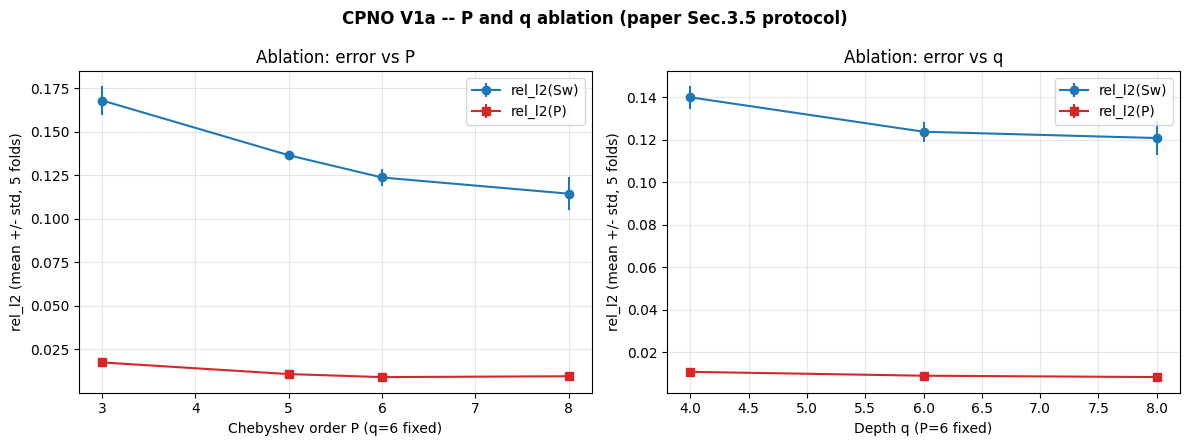

In [12]:
# -- CELL 12 - Ablation plot: error vs P and error vs q --
if not resumen_ablacion.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    df_p = resumen_ablacion[resumen_ablacion["q"] == BASELINE_DEPTH].sort_values("P")
    axes[0].errorbar(df_p["P"], df_p["rel_l2_Sw_mean"], yerr=df_p["rel_l2_Sw_std"],
                      marker="o", color="#1f77b4", label="rel_l2(Sw)")
    axes[0].errorbar(df_p["P"], df_p["rel_l2_P_mean"], yerr=df_p["rel_l2_P_std"],
                      marker="s", color="#d62728", label="rel_l2(P)")
    axes[0].set_xlabel(f"Chebyshev order P (q={BASELINE_DEPTH} fixed)")
    axes[0].set_ylabel("rel_l2 (mean +/- std, 5 folds)")
    axes[0].set_title("Ablation: error vs P")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    df_q = resumen_ablacion[resumen_ablacion["P"] == BASELINE_ORDER].sort_values("q")
    axes[1].errorbar(df_q["q"], df_q["rel_l2_Sw_mean"], yerr=df_q["rel_l2_Sw_std"],
                      marker="o", color="#1f77b4", label="rel_l2(Sw)")
    axes[1].errorbar(df_q["q"], df_q["rel_l2_P_mean"], yerr=df_q["rel_l2_P_std"],
                      marker="s", color="#d62728", label="rel_l2(P)")
    axes[1].set_xlabel(f"Depth q (P={BASELINE_ORDER} fixed)")
    axes[1].set_ylabel("rel_l2 (mean +/- std, 5 folds)")
    axes[1].set_title("Ablation: error vs q")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    fig.suptitle(f"{TECNICA_ID} {VERSION_ID} -- P and q ablation (paper Sec.3.5 protocol)", fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("Ablation skipped (RUN_ABLATION=False) -- no data to plot.")

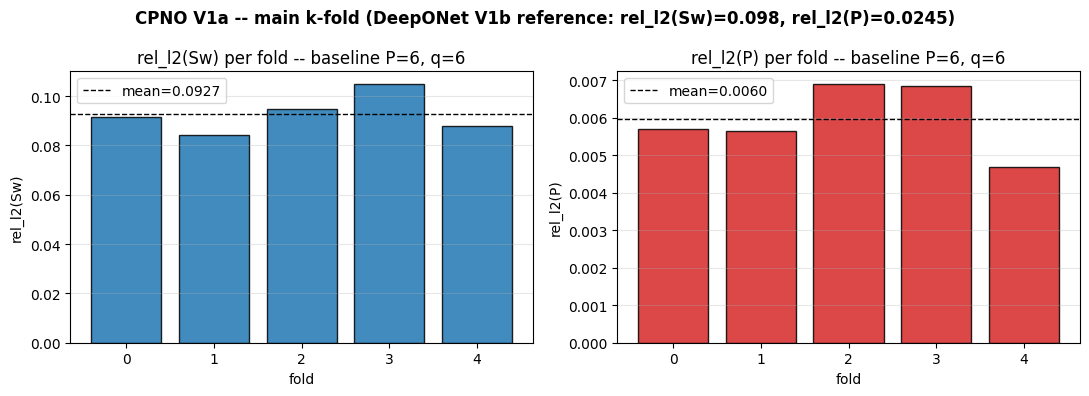

In [13]:
# -- CELL 13 - k-fold plot: rel_l2(Sw) and rel_l2(P) per fold (baseline P=6,q=6) --
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
folds_idx = [r["fold"] for r in resultados_kfold]
sw_vals_plot = [r["rel_l2_Sw"] for r in resultados_kfold]
p_vals_plot = [r["rel_l2_P"] for r in resultados_kfold]

for ax, vals, canal, color in zip(axes, [sw_vals_plot, p_vals_plot], ["Sw", "P"], ["#1f77b4", "#d62728"]):
    ax.bar(folds_idx, vals, color=color, edgecolor="k", alpha=0.85)
    ax.axhline(np.mean(vals), color="k", linestyle="--", linewidth=1,
               label=f"mean={np.mean(vals):.4f}")
    ax.set_xticks(folds_idx)
    ax.set_xlabel("fold")
    ax.set_ylabel(f"rel_l2({canal})")
    ax.set_title(f"rel_l2({canal}) per fold -- baseline P={BASELINE_ORDER}, q={BASELINE_DEPTH}")
    ax.legend()
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(f"{TECNICA_ID} {VERSION_ID} -- main k-fold "
             f"(DeepONet V1b reference: rel_l2(Sw)=0.098, rel_l2(P)=0.0245)", fontweight="bold")
plt.tight_layout()
plt.show()

In [14]:
# -- CELL 14 - Front maps: real OPM vs. CPNO (interactive: scenario/snapshot/field) --
# INJ1/NA2 here are ONLY used to annotate the map (markers) -- they are not a model feature (see Sec.3).
INJ1_IJ_PLOT = (9, 39)
NA2_IJ_PLOT = (20, 35)


def reconstruct_grid(values_active):
    grid = np.full((NX, NY), np.nan, dtype=np.float32)
    grid[active_i, active_j] = values_active
    return grid


def plot_comparacion_cpno(escenario_idx, snapshot_idx, campo):
    canal = 0 if campo == "Sw" else 1
    ti_arr = np.full(N_ACTIVE, snapshot_idx, dtype=np.int64)
    coords_np = np.stack([x_active, y_active, t_norm[ti_arr]], axis=1).astype(np.float32)
    theta_np = np.repeat(theta_norm[escenario_idx:escenario_idx + 1], N_ACTIVE, axis=0)
    with torch.inference_mode():
        pred = model_final(
            torch.from_numpy(coords_np).to(device),
            torch.from_numpy(theta_np).to(device),
        ).cpu().numpy()
    pred[:, 1] = pred[:, 1] * p_sigma_final + p_mu_final

    real_active = sw_active[escenario_idx, snapshot_idx] if campo == "Sw" else p_active[escenario_idx, snapshot_idx]
    pred_map = reconstruct_grid(pred[:, canal])
    real_map = reconstruct_grid(real_active)
    error_map = np.abs(real_map - pred_map)

    rate_inj1, lrat_na2 = params[escenario_idx]
    t_years = time_days[snapshot_idx] / 365.25
    vmin, vmax = np.nanmin([real_map, pred_map]), np.nanmax([real_map, pred_map])

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    cmap = "Blues" if campo == "Sw" else "viridis"
    paneles = [
        (real_map, "Ground truth (OPM)", cmap, vmin, vmax),
        (pred_map, "Pure CPNO V1a prediction", cmap, vmin, vmax),
        (error_map, "Absolute error", "Reds", None, None),
    ]
    for ax, (data, title, cm, lo, hi) in zip(axes, paneles):
        im = ax.imshow(data.T, origin="lower", cmap=cm, aspect="auto", vmin=lo, vmax=hi)
        plt.colorbar(im, ax=ax, fraction=0.046)
        ax.plot(*INJ1_IJ_PLOT, "r^", markersize=10)
        ax.plot(*NA2_IJ_PLOT, "ko", markersize=10)
        ax.set_title(title, fontsize=10)

    fig.suptitle(
        f"{TECNICA_ID} {VERSION_ID} -- scenario {escenario_idx} "
        f"(RATE_INJ1={rate_inj1:.0f}, LRAT_NA2={lrat_na2:.0f}) -- "
        f"t={t_years:.2f} years -- field={campo}",
        fontsize=12, fontweight="bold",
    )
    plt.tight_layout()
    plt.show()

    err_rel = np.linalg.norm(error_map[active_i, active_j]) / np.linalg.norm(real_map[active_i, active_j])
    print(f"rel_l2({campo}) pointwise, scenario {escenario_idx}, t={t_years:.2f} years: {err_rel:.4f}")
    if campo == "Sw" and (np.nanmax(pred_map) > 1.05 or np.nanmin(pred_map) < -0.05):
        print(f"Note: Sw outside [0,1] in active cells -- expected for pure V1a (no sigmoid, "
              f"see Cell 10) -- range: [{np.nanmin(pred_map):.3f}, {np.nanmax(pred_map):.3f}].")


if model_final is not None:
    interact(
        plot_comparacion_cpno,
        escenario_idx=widgets.IntSlider(min=0, max=N_ESCENARIOS - 1, step=1, value=0, description="scenario"),
        snapshot_idx=widgets.IntSlider(min=0, max=N_T - 1, step=1, value=N_T - 1, description="snapshot"),
        campo=widgets.ToggleButtons(options=["Sw", "P"], description="field"),
    );
else:
    print("Final model not available (RUN_FINAL_MODEL=False) -- no maps to plot.")

interactive(children=(IntSlider(value=0, description='scenario', max=49), IntSlider(value=60, description='sna…

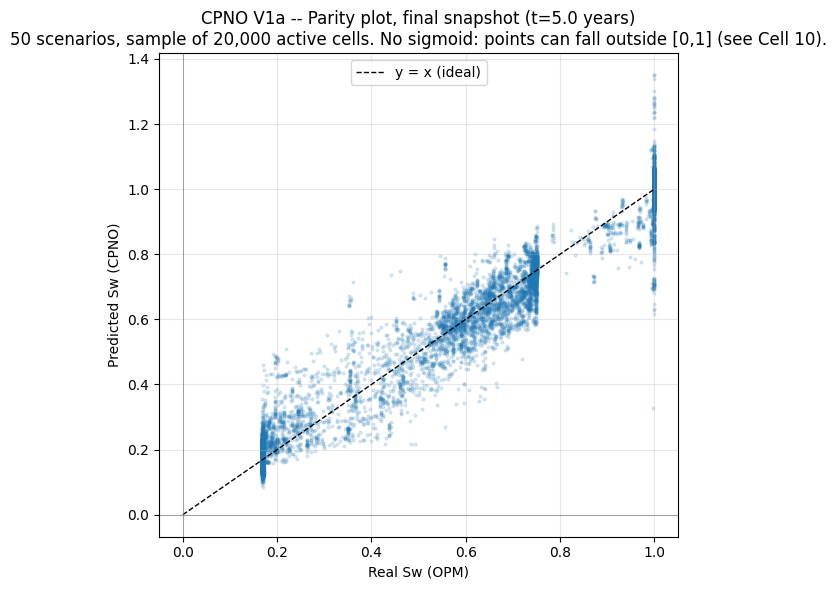

In [15]:
# -- CELL 15 - Parity plot: predicted Sw vs. real Sw (final snapshot, all scenarios) --
if model_final is not None:
    ti_last = np.full(N_ACTIVE, N_T - 1, dtype=np.int64)
    coords_last = np.stack([x_active, y_active, t_norm[ti_last]], axis=1).astype(np.float32)

    sw_pred_list = []
    with torch.inference_mode():
        for e in range(N_ESCENARIOS):
            theta_e = np.repeat(theta_norm[e:e + 1], N_ACTIVE, axis=0)
            pred_e = model_final(
                torch.from_numpy(coords_last).to(device),
                torch.from_numpy(theta_e).to(device),
            )[:, 0].cpu().numpy()
            sw_pred_list.append(pred_e)
    sw_pred_final = np.stack(sw_pred_list, axis=0)   # (N_ESCENARIOS, N_ACTIVE)
    sw_real_final = sw_active[:, -1, :]              # (N_ESCENARIOS, N_ACTIVE)

    rng_plot = np.random.default_rng(SEED)
    idx_muestra = rng_plot.choice(sw_pred_final.size, size=min(20000, sw_pred_final.size), replace=False)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(sw_real_final.ravel()[idx_muestra], sw_pred_final.ravel()[idx_muestra],
               s=4, alpha=0.15, color="#1f77b4")
    ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="y = x (ideal)")
    ax.axvline(0, color="gray", linewidth=0.5)
    ax.axhline(0, color="gray", linewidth=0.5)
    ax.set_xlabel("Real Sw (OPM)")
    ax.set_ylabel("Predicted Sw (CPNO)")
    ax.set_title(
        f"{TECNICA_ID} {VERSION_ID} -- Parity plot, final snapshot (t={time_days[-1] / 365.25:.1f} years)\n"
        f"{N_ESCENARIOS} scenarios, sample of {len(idx_muestra):,} active cells. "
        f"No sigmoid: points can fall outside [0,1] (see Cell 10)."
    )
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Final model not available -- no parity plot.")

## Notes and next steps

- **Correction (10/05/2026):** the first implementation of V1a mistakenly included `logK`, distances to wells and `sigmoid` on `Sw` -- UNISIM adaptations that are not in Algorithm 1 of the paper. These were fixed here; V1a stays faithful to Algorithm 1 (see header and artifact `chebyshev-unisim1-arquitectura`).
- The figure for the thesis is the main k-fold (mean +/- std), not the final in-sample error.
- The ablation uses a smaller budget than the main k-fold, but the same budget across all its configurations; it is useful for trend, not as a replacement for the main metric.
- If an ablation configuration improves clearly, it should be promoted to another version and repeated with the full `N_STEPS_KFOLD` before claiming an improvement.
- Expected diagnostic of pure V1a: without `sigmoid`, a fraction of the `Sw` points can fall outside `[0,1]` (Section 8). It is measured, not patched here.
- **V1b (future, non-blocking):** reintroduce `logK` + distances to wells + `sigmoid` on `Sw`, and compare against this pure V1a with the same *ceteris paribus* criterion already used for the data-driven-vs-physics-informed decision (artifact Sec.3.3) -- only this way can any improvement be attributed specifically to the UNISIM adaptations.
- Additional future work: physics-informed CPNO as a bridge to the PINN; a scenario outside the LHS chosen manually; variation of K only with new geological realizations.
- No point table is materialized: the online sampling is mathematically equivalent and reduces memory consumption.